# Proyek Analisis Data: E-Commerce Public Dataset
- **Nama:** Luthfia Ramadhani
- **Email:** luthfiaramadhani41@gmail.com
- **ID Dicoding:** luthfia_ramadhan20gf

## Menentukan Pertanyaan Bisnis

1. **Segmentasi Pelanggan (RFM Analysis):** Bagaimana distribusi segmentasi pelanggan berdasarkan skor *Recency*, *Frequency*, dan *Monetary* (RFM) pada periode transaksi September 2016 hingga Oktober 2018 untuk mengidentifikasi kelompok pelanggan paling bernilai (*Champions*) hingga pelanggan yang berisiko lepas (*At-Risk*) sebagai dasar penyusunan program loyalitas dan strategi retensi?
2. **Performa Kategori Produk:** Kategori produk apa saja yang mencatatkan volume penjualan tertinggi selama periode September 2016 hingga Oktober 2018 untuk menentukan prioritas pengelolaan stok inventaris dan strategi paket produk (*bundling*)?
3. **Metode Pembayaran:** Metode pembayaran apa yang paling sering digunakan oleh pelanggan beserta pola penggunaan cicilannya selama periode September 2016 hingga Oktober 2018 guna merancang program promosi cicilan dan kerja sama penyedia layanan pembayaran?
4. **Geospatial & Pendapatan Wilayah:** Negara bagian (*state*) mana di Brasil yang menyumbang jumlah pelanggan unik terbanyak serta total pendapatan tertinggi selama periode September 2016 hingga Oktober 2018 untuk menentukan prioritas lokasi pembangunan pusat pemenuhan pesanan (*fulfillment center*) dan kemitraan kurir lokal?
5. **Kepuasan Pelanggan & Logistik:** Bagaimana perbandingan rata-rata skor ulasan (*Review Score*) antara pesanan yang tiba tepat waktu dan pesanan yang mengalami keterlambatan pengiriman selama periode September 2016 hingga Oktober 2018 untuk mengevaluasi urgensi penerapan sistem peringatan dini (*early warning system*) serta kompensasi keterlambatan?

## Import Semua Packages/Library yang Digunakan

In [ ]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Konfigurasi tampilan visualisasi default
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

## Data Wrangling

### Gathering Data

#### Load E-Commerce Datasets

In [12]:
os.chdir('/content/drive/MyDrive/SUBMISSION PROYEK ANALISIS DATA')
customers_df = pd.read_csv("data/customers_dataset.csv")
orders_df = pd.read_csv("data/orders_dataset.csv")
order_payments_df = pd.read_csv("data/order_payments_dataset.csv")
order_items_df = pd.read_csv("data/order_items_dataset.csv")
order_reviews_df = pd.read_csv("data/order_reviews_dataset.csv")
products_df = pd.read_csv("data/products_dataset.csv")

print("Customers:", customers_df.shape)
print("Orders:", orders_df.shape)
print("Payments:", order_payments_df.shape)
print("Items:", order_items_df.shape)
print("Reviews:", order_reviews_df.shape)
print("Products:", products_df.shape)

Customers: (99441, 5)
Orders: (99441, 8)
Payments: (103886, 5)
Items: (112650, 7)
Reviews: (99224, 7)
Products: (32951, 9)


### **Insight:**
- **Skala Dataset dan Distribusi Data:** Keenam dataset utama berhasil dimuat tanpa kendala. `order_items_df` menjadi tabel dengan volume data terbesar mencapai **112.650 baris**, diikuti oleh `order_payments_df` sebanyak **103.886 baris**, sedangkan katalog `products_df` mencatat **32.951** entitas produk.
- **Korelasi Data Pelanggan dan Pesanan:** Jumlah total baris pada `customers_df` dan `orders_df` menunjukkan angka yang identik yaitu **99.441 baris**. Hal ini mengindikasikan bahwa setiap transaksi pesanan yang terdaftar berpasangan secara unik dengan satu data pelanggan.
- **Perilaku Transaksi Multi-Item & Metode Pembayaran:**
  * Volume data pada `order_items_df` (112.650) lebih tinggi daripada `orders_df` (99.441), yang mengindikasikan terdapat sebagian pelanggan yang membeli lebih dari satu barang (*multi-item*) dalam satu nomor pesanan yang sama.
  * Jumlah baris pada `order_payments_df` (103.886) juga melebihi total pesanan, menandakan adanya penggunaan lebih dari satu metode pembayaran (*split payment*) pada transaksi tertentu.
- **Tingkat Partisipasi Ulasan Pelanggan:** Total baris pada `order_reviews_df` tercatat sebanyak **99.224 baris**. Angka ini sedikit di bawah total pesanan (99.441), yang menunjukkan bahwa mayoritas pelanggan memberikan ulasan setelah bertransaksi, meskipun ada sebagian kecil pesanan yang belum memiliki ulasan.

### Assessing Data

#### Identifying Data Quality Problem

In [14]:
# 1. Memeriksa info tipe data dan jumlah data non-null untuk setiap DataFrame
print("=== CUSTOMERS ===")
customers_df.info()

print("\n=== ORDERS ===")
orders_df.info()

print("\n=== ORDER PAYMENTS ===")
order_payments_df.info()

print("\n=== ORDER ITEMS ===")
order_items_df.info()

print("\n=== ORDER REVIEWS ===")
order_reviews_df.info()

print("\n=== PRODUCTS ===")
products_df.info()


# 2. Memeriksa jumlah baris duplikat di setiap tabel
print("\n=== DUPLICATES CHECK ===")
print("Customers duplikat     :", customers_df.duplicated().sum())
print("Orders duplikat        :", orders_df.duplicated().sum())
print("Order Payments duplikat:", order_payments_df.duplicated().sum())
print("Order Items duplikat   :", order_items_df.duplicated().sum())
print("Order Reviews duplikat :", order_reviews_df.duplicated().sum())
print("Products duplikat      :", products_df.duplicated().sum())

=== CUSTOMERS ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 5 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   customer_id               99441 non-null  object
 1   customer_unique_id        99441 non-null  object
 2   customer_zip_code_prefix  99441 non-null  int64 
 3   customer_city             99441 non-null  object
 4   customer_state            99441 non-null  object
dtypes: int64(1), object(4)
memory usage: 3.8+ MB

=== ORDERS ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   order_id                       99441 non-null  object        
 1   customer_id                    99441 non-null  object        
 2   order_status                   99441 non-null  ob

**Steps to Take:**
* Memeriksa keberadaan baris data yang terduplikasi (*duplicate rows*) di seluruh tabel dataset.
* Memeriksa ketersediaan data dan identifikasi *missing values* pada setiap kolom di seluruh DataFrame.
* Memeriksa kesesuaian tipe data pada kolom yang menyimpan informasi tanggal/waktu agar sesuai dengan tipe data `datetime`.

**Insight:**
* **Masalah Duplikasi Data:** Seluruh tabel utama (`customers`, `orders`, `order_payments`, `order_items`, `order_reviews`, dan `products`) bersih dan bebas dari baris data duplikat (`0 duplikat`).
* **Masalah Missing Values:**
  * Pada `orders_df`, terdapat nilai yang hilang pada kolom status pengiriman: `order_approved_at` (160 nilai null), `order_delivered_carrier_date` (1.783 nilai null), dan `order_delivered_customer_date` (2.965 nilai null). Hal ini wajar terjadi karena ada pesanan yang belum disetujui, dibatalkan, atau masih dalam proses pengiriman.
  * Pada `order_reviews_df`, terdapat banyak nilai null pada kolom ulasan opsional: `review_comment_title` (87.656 nilai null) dan `review_comment_message` (58.247 nilai null), yang menunjukkan pembeli seringkali hanya memberikan rating bintang tanpa komentar tertulis.
  * Pada `products_df`, terdapat 610 nilai null pada kolom `product_category_name` (serta panjang nama/deskripsi dan jumlah foto produk), dan 2 nilai null pada informasi dimensi/berat produk (`product_weight_g`, `product_length_cm`, `product_height_cm`, `product_width_cm`).
* **Masalah Tipe Data:** Kolom tanggal pada `orders_df` (5 kolom), `order_items_df` (`shipping_limit_date`), serta `order_reviews_df` (`review_creation_date` & `review_answer_timestamp`) masih bertipe `object` (string) dan perlu dikonversi ke tipe data `datetime`.

### Cleaning Data

#### Fixing Data Quality Problem

In [16]:
# 1. Menangani missing values pada nama kategori produk
products_df['product_category_name'] = products_df['product_category_name'].fillna('unknown')

# 2. Mengonversi tipe data kolom tanggal pada tabel orders
datetime_orders = [
    'order_purchase_timestamp',
    'order_approved_at',
    'order_delivered_carrier_date',
    'order_delivered_customer_date',
    'order_estimated_delivery_date'
]
for col in datetime_orders:
    orders_df[col] = pd.to_datetime(orders_df[col])

# 3. Mengonversi tipe data kolom tanggal pada tabel order_items dan order_reviews
order_items_df['shipping_limit_date'] = pd.to_datetime(order_items_df['shipping_limit_date'])
order_reviews_df['review_creation_date'] = pd.to_datetime(order_reviews_df['review_creation_date'])
order_reviews_df['review_answer_timestamp'] = pd.to_datetime(order_reviews_df['review_answer_timestamp'])

# 4. Verifikasi hasil pembersihan data
print("Sisa missing value pada product_category_name:", products_df['product_category_name'].isna().sum())
print("Tipe data order_purchase_timestamp:", orders_df['order_purchase_timestamp'].dtype)

Sisa missing value pada product_category_name: 0
Tipe data order_purchase_timestamp: datetime64[ns]


**Insight:**
* **Penanganan Missing Values:** Nilai kosong pada kolom `product_category_name` di tabel `products_df` telah diisi dengan label `'unknown'` agar seluruh transaksi produk tetap tercatat dalam pengelompokan kategori. Sementara itu, nilai kosong (*null*) pada `orders_df` dan `order_reviews_df` tetap dipertahankan (*kept as null*) karena mencerminkan kondisi riil di lapangan (pesanan yang memang belum/tidak terkirim, serta pembeli yang memilih tidak menulis komentar ulasan).
* **Koreksi Tipe Data:** Seluruh kolom yang menyimpan informasi tanggal/waktu pada `orders_df`, `order_items_df`, dan `order_reviews_df` telah berhasil dikonversi ke tipe data `datetime64[ns]` agar siap dianalisis berdasarkan tren waktu (*time-series analysis*).
* **Keutuhan Data:** Seluruh tabel utama yang digunakan telah dipastikan bebas dari baris duplikat (`0 duplikat`) sehingga valid untuk digabungkan pada tahap eksplorasi data.

## Exploratory Data Analysis (EDA)

### Explore E-Commerce Data


In [17]:
# 0. Mengecek rentang waktu transaksi pada dataset
min_date = orders_df['order_purchase_timestamp'].min()
max_date = orders_df['order_purchase_timestamp'].max()
print(f"Rentang waktu transaksi: {min_date} hingga {max_date}\n")

# Pertanyaan 2: Eksplorasi Kategori Produk Terlaris
order_items_products_df = pd.merge(
    left=order_items_df,
    right=products_df,
    how="left",
    on="product_id"
)
top_categories = order_items_products_df.groupby("product_category_name")["order_item_id"].count().sort_values(ascending=False).reset_index()
top_categories.columns = ["product_category_name", "total_items_sold"]
print("=== TOP 5 KATEGORI PRODUK TERLARIS ===")
print(top_categories.head(5), "\n")

# Pertanyaan 3: Eksplorasi Metode Pembayaran dan Pola Cicilan
payment_counts = order_payments_df.groupby("payment_type")["order_id"].nunique().sort_values(ascending=False).reset_index()
payment_counts.columns = ["payment_type", "unique_orders"]
print("=== METODE PEMBAYARAN (BERDASARKAN PESANAN UNIK) ===")
print(payment_counts, "\n")

credit_card_df = order_payments_df[order_payments_df["payment_type"] == "credit_card"]
installment_summary = credit_card_df["payment_installments"].describe()
print("=== STATISTIK CICILAN KARTU KREDIT ===")
print(installment_summary)
print("Persentase transaksi kartu kredit menggunakan cicilan (> 1 kali):",
      round((credit_card_df["payment_installments"] > 1).mean() * 100, 2), "%\n")

# Pertanyaan 4: Eksplorasi Pelanggan Unik dan Total Pendapatan per Negara Bagian (State)
orders_customers_payments_df = pd.merge(
    left=orders_df,
    right=customers_df,
    how="left",
    on="customer_id"
).merge(
    right=order_payments_df.groupby("order_id")["payment_value"].sum().reset_index(),
    how="inner",
    on="order_id"
)

state_performance = orders_customers_payments_df.groupby("customer_state").agg(
    unique_customers=("customer_unique_id", "nunique"),
    total_revenue=("payment_value", "sum")
).sort_values(by="total_revenue", ascending=False).reset_index()
print("=== TOP 5 NEGARA BAGIAN BERDASARKAN PENDAPATAN & PELANGGAN UNIK ===")
print(state_performance.head(5), "\n")

# Pertanyaan 5: Kepuasan Pelanggan & Logistik (Keterlambatan dibandingkan dengan Skor Ulasan)
# Hanya menyertakan pesanan yang sudah benar-benar tiba di pelanggan (tanggal tiba tidak kosong)
delivered_orders_df = orders_df[orders_df["order_delivered_customer_date"].notna()].copy()
delivered_orders_df["delivery_status"] = np.where(
    delivered_orders_df["order_delivered_customer_date"] > delivered_orders_df["order_estimated_delivery_date"],
    "Terlambat",
    "Tepat Waktu"
)

delivery_reviews_df = pd.merge(
    left=delivered_orders_df,
    right=order_reviews_df,
    how="inner",
    on="order_id"
)

delivery_review_summary = delivery_reviews_df.groupby("delivery_status").agg(
    total_reviews=("review_id", "count"),
    unique_orders=("order_id", "nunique"),
    avg_review_score=("review_score", "mean")
).reset_index()
print("=== PERBANDINGAN SKOR ULASAN BERDASARKAN KETEPATAN PENGIRIMAN ===")
print(delivery_review_summary)

Rentang waktu transaksi: 2016-09-04 21:15:19 hingga 2018-10-17 17:30:18

=== TOP 5 KATEGORI PRODUK TERLARIS ===
    product_category_name  total_items_sold
0         cama_mesa_banho             11115
1            beleza_saude              9670
2           esporte_lazer              8641
3        moveis_decoracao              8334
4  informatica_acessorios              7827 

=== METODE PEMBAYARAN (BERDASARKAN PESANAN UNIK) ===
  payment_type  unique_orders
0  credit_card          76505
1       boleto          19784
2      voucher           3866
3   debit_card           1528
4  not_defined              3 

=== STATISTIK CICILAN KARTU KREDIT ===
count    76795.000000
mean         3.507155
std          2.850990
min          0.000000
25%          1.000000
50%          3.000000
75%          5.000000
max         24.000000
Name: payment_installments, dtype: float64
Persentase transaksi kartu kredit menggunakan cicilan (> 1 kali): 66.85 %

=== TOP 5 NEGARA BAGIAN BERDASARKAN PENDAPATAN & PELAN

**Insight:**
* **Skala Transaksi dan Pelanggan Unik:** Sistem mencatat total **99.441 transaksi pesanan** dari **96.096 pelanggan unik** pada periode **September 2016 hingga Oktober 2018**. Selisih **3.345 pesanan** menunjukkan masih rendahnya tingkat pembelian berulang (*repeat order*).
* **Kategori Produk Terlaris:** Kategori `cama_mesa_banho` (perlengkapan rumah tangga) menempati urutan pertama berdasarkan volume penjualan sebanyak **11.115 item**, diikuti oleh `beleza_saude` (kecantikan dan kesehatan) dengan **9.670 item**, serta `esporte_lazer` (olahraga dan rekreasi) sebanyak **8.641 item**.
* **Dominasi Metode Pembayaran dan Preferensi Cicilan:** Kartu kredit (`credit_card`) menjadi metode pembayaran paling dominan dengan **76.505 pesanan**, jauh melampaui metode `boleto` (**19.784 pesanan**) dan `voucher` (**3.866 pesanan**). Sebanyak **66,85%** dari transaksi kartu kredit menggunakan fasilitas cicilan (lebih dari 1 kali pembayaran) dengan rata-rata **3,51 kali** cicilan (median **3 kali**), membuktikan tingginya preferensi pelanggan terhadap pembayaran bertahap.
* **Konsentrasi Wilayah Pelanggan:** Negara bagian **São Paulo (`SP`)** mendominasi pasar secara signifikan dengan **40.301 pelanggan unik** dan total pendapatan mencapai **5.998.226,96 BRL**, diikuti oleh **Rio de Janeiro (`RJ`)** (**12.384 pelanggan unik**; **2.144.379,69 BRL**) dan **Minas Gerais (`MG`)** (**11.259 pelanggan unik**; **1.872.257,26 BRL**).
* **Dampak Keterlambatan Pengiriman terhadap Ulasan:** Ketepatan waktu pengiriman sangat memengaruhi kepuasan pelanggan. Dari pesanan yang telah diterima pelanggan, pengiriman **tepat waktu** (**88.168 pesanan**; **88.658 ulasan**) memperoleh rata-rata skor ulasan **4,29**, sedangkan pengiriman **terlambat** (**7.662 pesanan**; **7.701 ulasan**) mengalami penurunan skor ulasan drastis hingga rata-rata **2,57**.

## Visualization & Explanatory Analysis

### **Pertanyaan 1:**
Bagaimana distribusi segmentasi pelanggan berdasarkan skor RFM (*Recency*, *Frequency*, *Monetary*) pada periode September 2016 hingga Oktober 2018 untuk mengidentifikasi kelompok pelanggan paling bernilai (*Champions*) dan pelanggan yang berisiko lepas (*At-Risk*) dalam merancang program retensi?

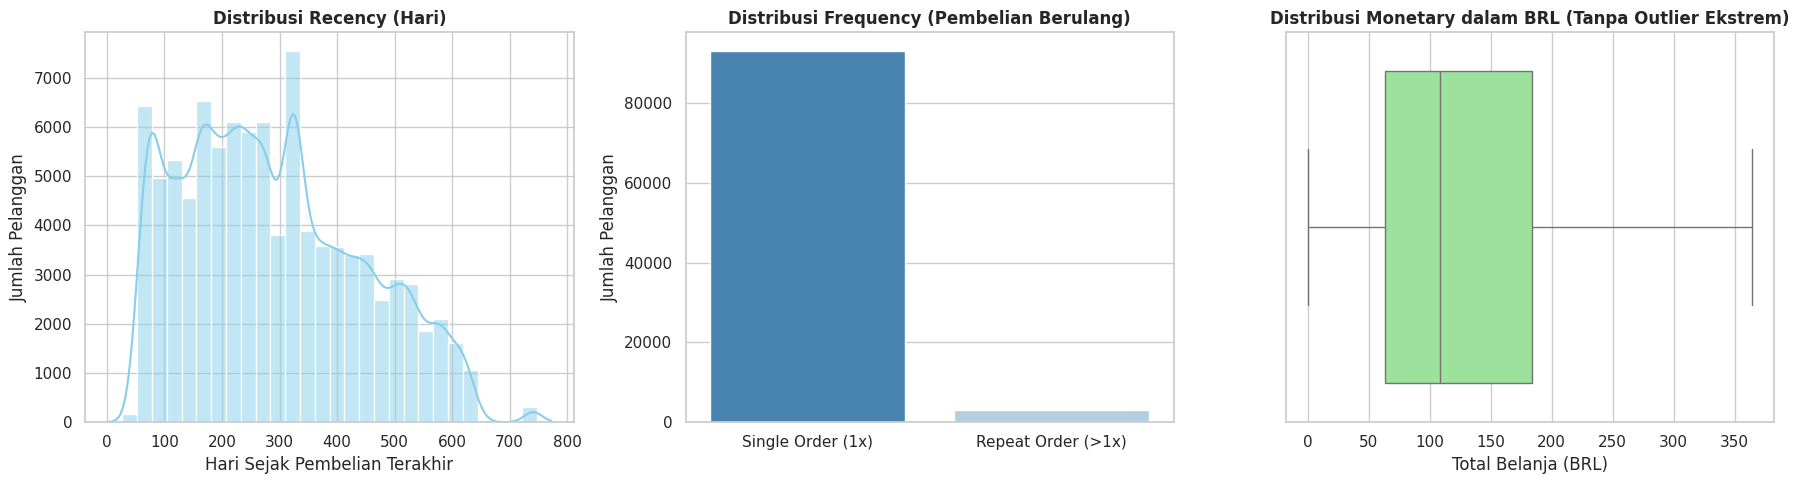

Total Pelanggan Unik: 96095
Single Order (1x)   : 93098 (96.88%)
Repeat Order (>1x)  : 2997 (3.12%)
Median Recency      : 269.0 hari | Rata-rata: 288.73 hari
Median Monetary     : 108.0 BRL | Rata-rata: 166.59 BRL


In [18]:
# Menghitung nilai Recency, Frequency, dan Monetary per pelanggan unik
recent_date = orders_customers_payments_df["order_purchase_timestamp"].max() + pd.Timedelta(days=1)

rfm_df = orders_customers_payments_df.groupby("customer_unique_id", as_index=False).agg(
    max_order_timestamp=("order_purchase_timestamp", "max"),
    frequency=("order_id", "nunique"),
    monetary=("payment_value", "sum")
)
rfm_df["recency"] = (recent_date - rfm_df["max_order_timestamp"]).dt.days

# Membuat visualisasi distribusi RFM
fig, ax = plt.subplots(nrows=1, ncols=3, figsize=(18, 5))

# 1. Visualisasi Recency
sns.histplot(rfm_df["recency"], bins=30, kde=True, ax=ax[0], color="skyblue")
ax[0].set_title("Distribusi Recency (Hari)", fontsize=12, fontweight="bold")
ax[0].set_xlabel("Hari Sejak Pembelian Terakhir")
ax[0].set_ylabel("Jumlah Pelanggan")

# 2. Visualisasi Frequency (Perbandingan Single Order dibandingkan dengan Repeat Order)
freq_labels = ["Single Order (1x)", "Repeat Order (>1x)"]
freq_values = [(rfm_df["frequency"] == 1).sum(), (rfm_df["frequency"] > 1).sum()]
sns.barplot(
    x=freq_labels,
    y=freq_values,
    hue=freq_labels,
    palette="Blues_r",
    legend=False,
    ax=ax[1]
)
ax[1].set_title("Distribusi Frequency (Pembelian Berulang)", fontsize=12, fontweight="bold")
ax[1].set_ylabel("Jumlah Pelanggan")

# 3. Visualisasi Monetary (Distribusi Total Belanja Pelanggan)
sns.boxplot(x=rfm_df["monetary"], ax=ax[2], color="lightgreen", showfliers=False)
ax[2].set_title("Distribusi Monetary dalam BRL (Tanpa Outlier Ekstrem)", fontsize=12, fontweight="bold")
ax[2].set_xlabel("Total Belanja (BRL)")

plt.tight_layout()
plt.show()

# Menampilkan ringkasan angka RFM untuk akurasi Insight
print("Total Pelanggan Unik:", len(rfm_df))
print("Single Order (1x)   :", freq_values[0], f"({freq_values[0]/len(rfm_df)*100:.2f}%)")
print("Repeat Order (>1x)  :", freq_values[1], f"({freq_values[1]/len(rfm_df)*100:.2f}%)")
print("Median Recency      :", rfm_df["recency"].median(), "hari | Rata-rata:", round(rfm_df["recency"].mean(), 2), "hari")
print("Median Monetary     :", round(rfm_df["monetary"].median(), 2), "BRL | Rata-rata:", round(rfm_df["monetary"].mean(), 2), "BRL")

**Insight:**
* **Recency:** Dari total **96.095 pelanggan unik**, mayoritas memiliki rentang waktu transaksi terakhir (*recency*) antara **100 hingga 400 hari** yang lalu, dengan nilai median **269 hari** (rata-rata **288,73 hari**). Hal ini menunjukkan sebagian besar basis pelanggan tergolong pasif atau berisiko lepas (*At-Risk*) karena sudah lama tidak melakukan pembelian kembali.
* **Frequency:** Distribusi frekuensi transaksi didominasi secara ekstrem oleh kelompok pelanggan **Single Order** sebanyak **93.098 pelanggan (96,88%)** yang hanya bertransaksi 1 kali. Sementara itu, pelanggan yang melakukan pembelian berulang (**Repeat Order**) hanya berjumlah **2.997 pelanggan (3,12%)**, sehingga diperlukan strategi retensi dan loyalitas pelanggan yang lebih agresif.
* **Monetary:** Berdasarkan distribusi utama (tanpa pencilan ekstrem), nilai total belanja mayoritas pelanggan terkonsentrasi pada rentang **60 hingga 185 BRL** dengan nilai tengah (median) sebesar **108,00 BRL** (rata-rata keseluruhan **166,59 BRL**). Sekelompok kecil pelanggan dengan nilai transaksi jauh di atas kuartil atas dan frekuensi berulang merupakan segmen paling bernilai (*Champions*) yang perlu diprioritaskan.

### **Pertanyaan 2:**
Kategori produk apa saja yang mencatatkan volume penjualan tertinggi dan kontribusi pendapatan terbesar selama periode September 2016 hingga Oktober 2018 untuk menentukan prioritas alokasi stok serta program bundling promosi?

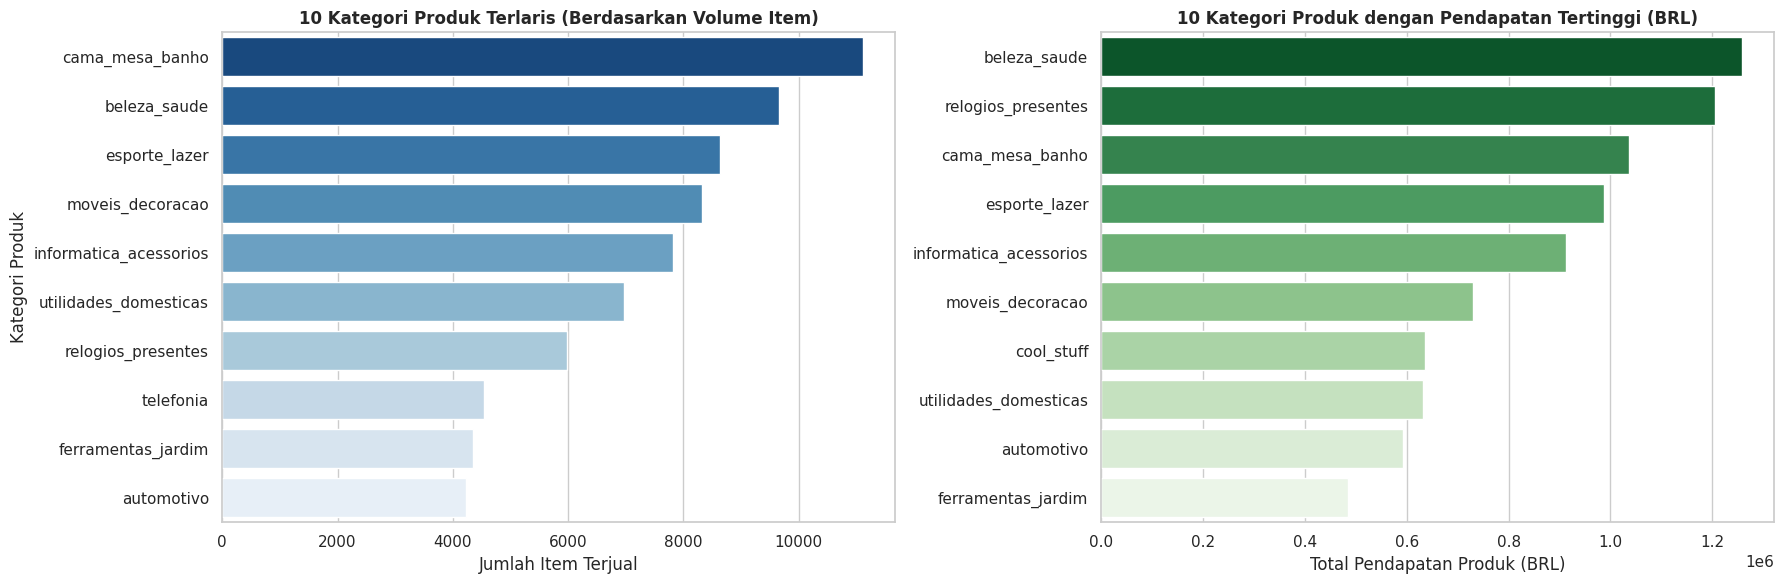

=== TOP 3 VOLUME PENJUALAN ===
   product_category_name  total_items_sold  total_revenue
13       cama_mesa_banho             11115     1036988.68
11          beleza_saude              9670     1258681.34
32         esporte_lazer              8641      988048.97 

=== TOP 3 PENDAPATAN PRODUK ===
   product_category_name  total_revenue  total_items_sold
11          beleza_saude     1258681.34              9670
66    relogios_presentes     1205005.68              5991
13       cama_mesa_banho     1036988.68             11115


In [19]:
# Menggabungkan data item pesanan dengan informasi kategori produk
category_performance = order_items_products_df.groupby("product_category_name", as_index=False).agg(
    total_items_sold=("order_item_id", "count"),
    total_revenue=("price", "sum")
)

top_10_volume = category_performance.sort_values(by="total_items_sold", ascending=False).head(10)
top_10_revenue = category_performance.sort_values(by="total_revenue", ascending=False).head(10)

# Membuat visualisasi dua panel berdampingan
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(18, 6))

# Panel 1: Top 10 Kategori Berdasarkan Jumlah Item Terjual
sns.barplot(
    data=top_10_volume,
    x="total_items_sold",
    y="product_category_name",
    hue="product_category_name",
    palette="Blues_r",
    legend=False,
    ax=ax[0]
)
ax[0].set_title("10 Kategori Produk Terlaris (Berdasarkan Volume Item)", fontsize=12, fontweight="bold")
ax[0].set_xlabel("Jumlah Item Terjual")
ax[0].set_ylabel("Kategori Produk")

# Panel 2: Top 10 Kategori Berdasarkan Total Pendapatan (Harga Produk)
sns.barplot(
    data=top_10_revenue,
    x="total_revenue",
    y="product_category_name",
    hue="product_category_name",
    palette="Greens_r",
    legend=False,
    ax=ax[1]
)
ax[1].set_title("10 Kategori Produk dengan Pendapatan Tertinggi (BRL)", fontsize=12, fontweight="bold")
ax[1].set_xlabel("Total Pendapatan Produk (BRL)")
ax[1].set_ylabel("")

plt.tight_layout()
plt.show()

# Menampilkan ringkasan angka Top 3 Volume dan Top 3 Pendapatan
print("=== TOP 3 VOLUME PENJUALAN ===")
print(top_10_volume[["product_category_name", "total_items_sold", "total_revenue"]].head(3), "\n")
print("=== TOP 3 PENDAPATAN PRODUK ===")
print(top_10_revenue[["product_category_name", "total_revenue", "total_items_sold"]].head(3))

**Insight:**
* **Pemimpin Volume Penjualan:** Kategori `cama_mesa_banho` (perlengkapan rumah tangga) menempati peringkat pertama dari sisi kuantitas dengan **11.115 item terjual** (pendapatan **1.036.988,68 BRL**), diikuti oleh `beleza_saude` (**9.670 item**) dan `esporte_lazer` (**8.641 item**).
* **Pemimpin Kontribusi Pendapatan:** Dari sisi nilai penjualan, kategori `beleza_saude` (kecantikan dan kesehatan) menjadi penyumbang pendapatan tertinggi sebesar **1.258.681,34 BRL**, disusul oleh `relogios_presentes` (jam tangan dan hadiah) sebesar **1.205.005,68 BRL** meskipun jumlah item terjualnya berada di urutan ke-7 (**5.991 item**), serta `cama_mesa_banho` di urutan ketiga (**1.036.988,68 BRL**).
* **Implikasi Strategi Bisnis:** Perbedaan antara pemimpin volume dan pemimpin pendapatan menunjukkan bahwa kategori `cama_mesa_banho` mengandalkan perputaran barang cepat dengan harga satuan relatif terjangkau, sedangkan `relogios_presentes` dan `beleza_saude` memiliki harga rata-rata per unit lebih tinggi. Ketiganya merupakan kandidat utama untuk prioritas ketersediaan stok (*safety stock*) serta kampanye paket *bundling*.

### **Pertanyaan 3:**
Metode pembayaran apa yang paling mendominasi transaksi serta bagaimana pola penggunaan cicilan kartu kredit selama periode September 2016 hingga Oktober 2018 untuk merancang strategi promosi pembayaran yang efektif?

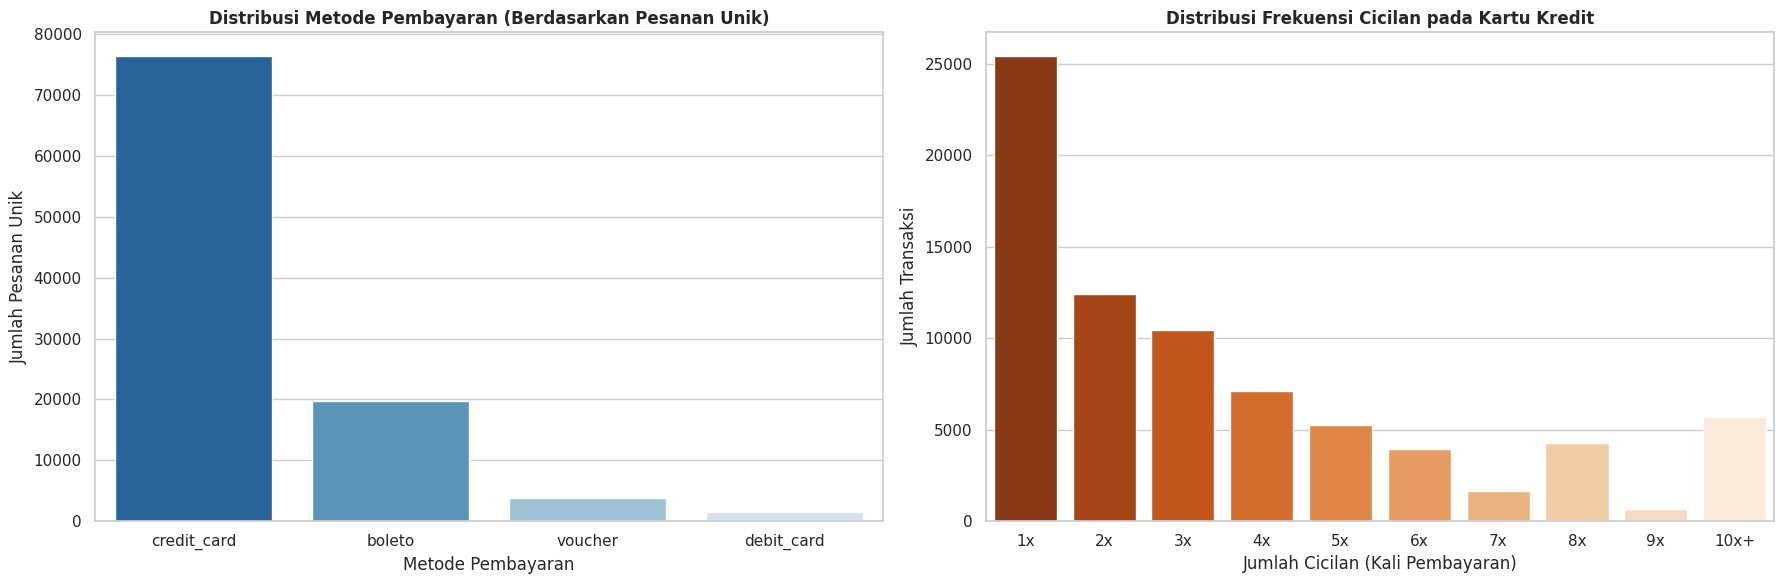

=== RINGKASAN METODE PEMBAYARAN ===
payment_type  unique_orders
 credit_card          76505
      boleto          19784
     voucher           3866
  debit_card           1528 

Total transaksi kartu kredit valid (>=1x): 76793
Transaksi menggunakan cicilan (>1x)     : 51338 (66.85%)
Rata-rata cicilan kartu kredit          : 3.51 kali (Median: 3 kali)


In [20]:
# 1. Menyiapkan data distribusi metode pembayaran (berdasarkan pesanan unik)
payment_dist = order_payments_df.groupby("payment_type", as_index=False).agg(
    unique_orders=("order_id", "nunique")
).sort_values(by="unique_orders", ascending=False)
payment_dist = payment_dist[payment_dist["payment_type"] != "not_defined"]

# 2. Menyiapkan data distribusi cicilan pada transaksi kartu kredit
cc_payments = order_payments_df[
    (order_payments_df["payment_type"] == "credit_card") &
    (order_payments_df["payment_installments"] >= 1)
].copy()
cc_payments["installment_group"] = cc_payments["payment_installments"].apply(
    lambda x: f"{int(x)}x" if x < 10 else "10x+"
)
installment_order = ["1x", "2x", "3x", "4x", "5x", "6x", "7x", "8x", "9x", "10x+"]
installment_dist = cc_payments["installment_group"].value_counts().reindex(installment_order).reset_index()
installment_dist.columns = ["installment_group", "total_transactions"]

# Membuat visualisasi dua panel berdampingan
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(18, 6))

# Panel 1: Distribusi Metode Pembayaran
sns.barplot(
    data=payment_dist,
    x="payment_type",
    y="unique_orders",
    hue="payment_type",
    palette="Blues_r",
    legend=False,
    ax=ax[0]
)
ax[0].set_title("Distribusi Metode Pembayaran (Berdasarkan Pesanan Unik)", fontsize=12, fontweight="bold")
ax[0].set_xlabel("Metode Pembayaran")
ax[0].set_ylabel("Jumlah Pesanan Unik")

# Panel 2: Distribusi Frekuensi Cicilan Kartu Kredit
sns.barplot(
    data=installment_dist,
    x="installment_group",
    y="total_transactions",
    hue="installment_group",
    palette="Oranges_r",
    legend=False,
    ax=ax[1]
)
ax[1].set_title("Distribusi Frekuensi Cicilan pada Kartu Kredit", fontsize=12, fontweight="bold")
ax[1].set_xlabel("Jumlah Cicilan (Kali Pembayaran)")
ax[1].set_ylabel("Jumlah Transaksi")

plt.tight_layout()
plt.show()

# Menampilkan ringkasan angka untuk verifikasi Insight
total_cc = len(cc_payments)
installment_gt1 = (cc_payments["payment_installments"] > 1).sum()
print("=== RINGKASAN METODE PEMBAYARAN ===")
print(payment_dist.to_string(index=False), "\n")
print(f"Total transaksi kartu kredit valid (>=1x): {total_cc}")
print(f"Transaksi menggunakan cicilan (>1x)     : {installment_gt1} ({installment_gt1/total_cc*100:.2f}%)")
print(f"Rata-rata cicilan kartu kredit          : {cc_payments['payment_installments'].mean():.2f} kali (Median: {cc_payments['payment_installments'].median():.0f} kali)")

**Insight:**
* **Dominasi Kartu Kredit:** Metode pembayaran kartu kredit (`credit_card`) mendominasi transaksi secara mutlak dengan **76.505 pesanan unik**, jauh mengungguli metode `boleto` (**19.784 pesanan**), `voucher` (**3.866 pesanan**), dan `debit_card` (**1.528 pesanan**).
* **Preferensi Tinggi terhadap Skema Cicilan:** Dari seluruh transaksi kartu kredit yang valid (**76.793 transaksi**), sebanyak **66,85%** (**51.338 transaksi**) menggunakan skema pembayaran cicilan lebih dari 1 kali, dengan rata-rata **3,51 kali** cicilan (nilai tengah **3 kali**) serta lonjakan minat yang terlihat jelas pada tenor **2x, 3x, hingga 10x ke atas**.
* **Rekomendasi Bisnis:** Tingginya ketergantungan pelanggan pada kartu kredit dan fasilitas cicilan menjadi peluang strategis bagi perusahaan untuk bekerja sama dengan mitra perbankan dalam menawarkan program **cicilan 0%** atau potongan harga khusus bagi pembayaran menggunakan kartu kredit guna meningkatkan nilai rata-rata transaksi (*average order value*).

### **Pertanyaan 4:**
Bagaimana persebaran geografis jumlah pelanggan unik dan total pendapatan berdasarkan negara bagian di Brasil selama periode September 2016 hingga Oktober 2018 untuk menentukan lokasi prioritas pengembangan pusat pemenuhan pesanan (*fulfillment center*)?

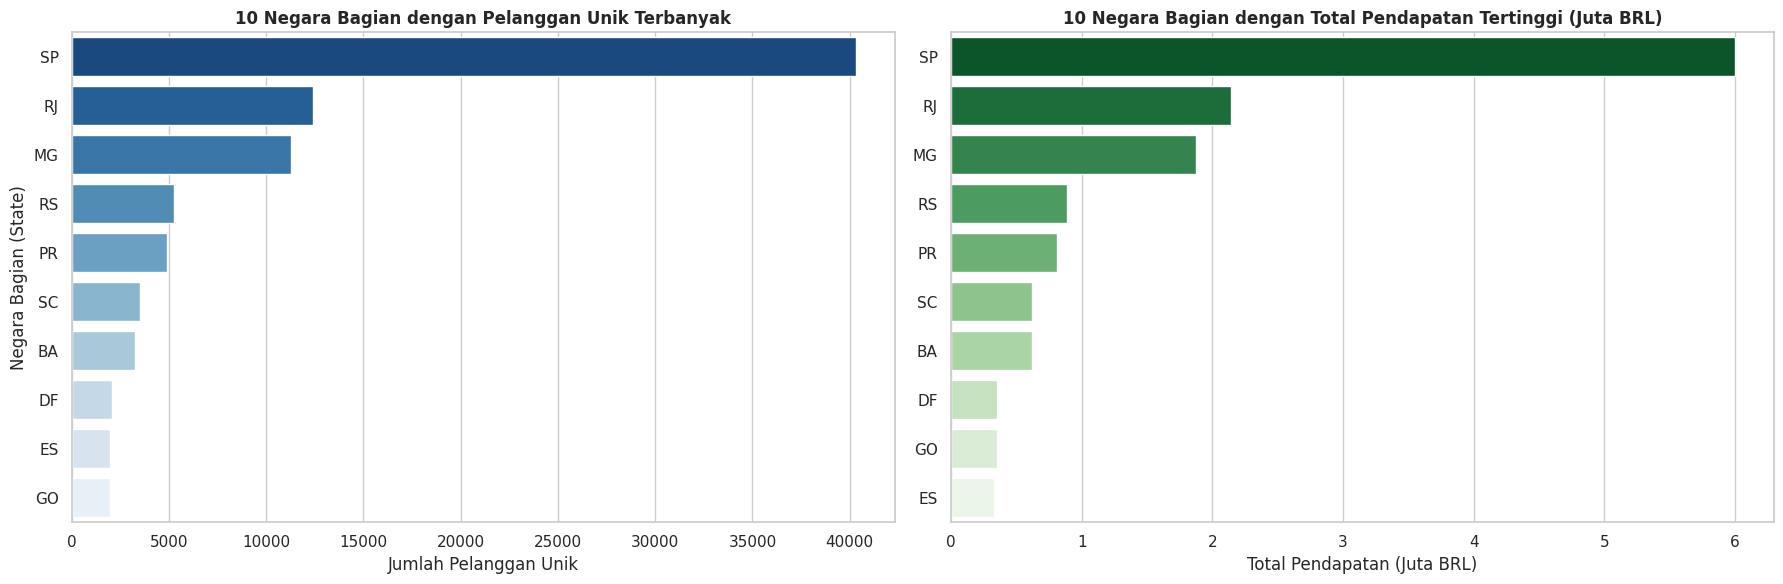

=== TOP 5 NEGARA BAGIAN (PELANGGAN UNIK & PENDAPATAN) ===
customer_state  unique_customers  total_revenue
            SP             40301     5998226.96
            RJ             12384     2144379.69
            MG             11259     1872257.26
            RS              5277      890898.54
            PR              4882      811156.38 

Kontribusi Gabungan SP, RJ, dan MG terhadap Pelanggan Unik: 66.51%
Kontribusi Gabungan SP, RJ, dan MG terhadap Total Pendapatan: 62.56%


In [21]:
# Menggunakan dasar perhitungan yang konsisten dengan tahap EDA (orders_customers_payments_df)
state_geo_summary = orders_customers_payments_df.groupby("customer_state", as_index=False).agg(
    unique_customers=("customer_unique_id", "nunique"),
    total_revenue=("payment_value", "sum")
)

top_10_customers_state = state_geo_summary.sort_values(by="unique_customers", ascending=False).head(10)
top_10_revenue_state = state_geo_summary.sort_values(by="total_revenue", ascending=False).head(10)

# Membuat visualisasi dua panel berdampingan
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(18, 6))

# Panel 1: Top 10 Negara Bagian Berdasarkan Pelanggan Unik
sns.barplot(
    data=top_10_customers_state,
    x="unique_customers",
    y="customer_state",
    hue="customer_state",
    palette="Blues_r",
    legend=False,
    ax=ax[0]
)
ax[0].set_title("10 Negara Bagian dengan Pelanggan Unik Terbanyak", fontsize=12, fontweight="bold")
ax[0].set_xlabel("Jumlah Pelanggan Unik")
ax[0].set_ylabel("Negara Bagian (State)")

# Panel 2: Top 10 Negara Bagian Berdasarkan Total Pendapatan (Juta BRL)
top_10_revenue_state = top_10_revenue_state.copy()
top_10_revenue_state["revenue_million"] = top_10_revenue_state["total_revenue"] / 1_000_000
sns.barplot(
    data=top_10_revenue_state,
    x="revenue_million",
    y="customer_state",
    hue="customer_state",
    palette="Greens_r",
    legend=False,
    ax=ax[1]
)
ax[1].set_title("10 Negara Bagian dengan Total Pendapatan Tertinggi (Juta BRL)", fontsize=12, fontweight="bold")
ax[1].set_xlabel("Total Pendapatan (Juta BRL)")
ax[1].set_ylabel("")

plt.tight_layout()
plt.show()

# Menampilkan ringkasan angka Top 5 Negara Bagian serta proporsi wilayah Tenggara (SP, RJ, MG)
total_all_customers = state_geo_summary["unique_customers"].sum()
total_all_revenue = state_geo_summary["total_revenue"].sum()
top3_states = state_geo_summary[state_geo_summary["customer_state"].isin(["SP", "RJ", "MG"])]

print("=== TOP 5 NEGARA BAGIAN (PELANGGAN UNIK & PENDAPATAN) ===")
print(top_10_revenue_state[["customer_state", "unique_customers", "total_revenue"]].head(5).to_string(index=False), "\n")
print(f"Kontribusi Gabungan SP, RJ, dan MG terhadap Pelanggan Unik: {top3_states['unique_customers'].sum() / total_all_customers * 100:.2f}%")
print(f"Kontribusi Gabungan SP, RJ, dan MG terhadap Total Pendapatan: {top3_states['total_revenue'].sum() / total_all_revenue * 100:.2f}%")

**Insight:**
* **Dominasi Pasar oleh São Paulo (`SP`):** Negara bagian **São Paulo (`SP`)** menduduki peringkat pertama secara signifikan dengan **40.301 pelanggan unik** dan total pendapatan sebesar **5.998.226,96 BRL**, jauh melampaui **Rio de Janeiro (`RJ`)** (**12.384 pelanggan unik**; **2.144.379,69 BRL**) serta **Minas Gerais (`MG`)** (**11.259 pelanggan unik**; **1.872.257,26 BRL**).
* **Konsentrasi Wilayah Tenggara Brasil:** Secara keseluruhan, ketiga negara bagian utama tersebut (`SP`, `RJ`, dan `MG`) menyumbang **66,51%** dari total basis pelanggan unik dan **62,56%** dari total pendapatan platform. Sementara itu, negara bagian wilayah selatan seperti **Rio Grande do Sul (`RS`)** (**5.277 pelanggan unik**; **890.898,54 BRL**) dan **Paraná (`PR`)** (**4.882 pelanggan unik**; **811.156,38 BRL**) menempati peringkat keempat dan kelima.
* **Implikasi Operasional Logistik:** Tingginya konsentrasi permintaan di kawasan tenggara Brasil (`SP`, `RJ`, dan `MG`) menjadikan wilayah ini sebagai prioritas utama untuk penempatan dan optimalisasi kapasitas pusat pemenuhan pesanan (*fulfillment center*) guna mempercepat waktu pengiriman serta menekan biaya logistik.

### **Pertanyaan 5:**
Seberapa besar pengaruh ketepatan waktu pengiriman terhadap tingkat kepuasan pelanggan (skor ulasan) selama periode September 2016 hingga Oktober 2018 sebagai dasar perancangan sistem peringatan dini (*early warning system*) logistik?

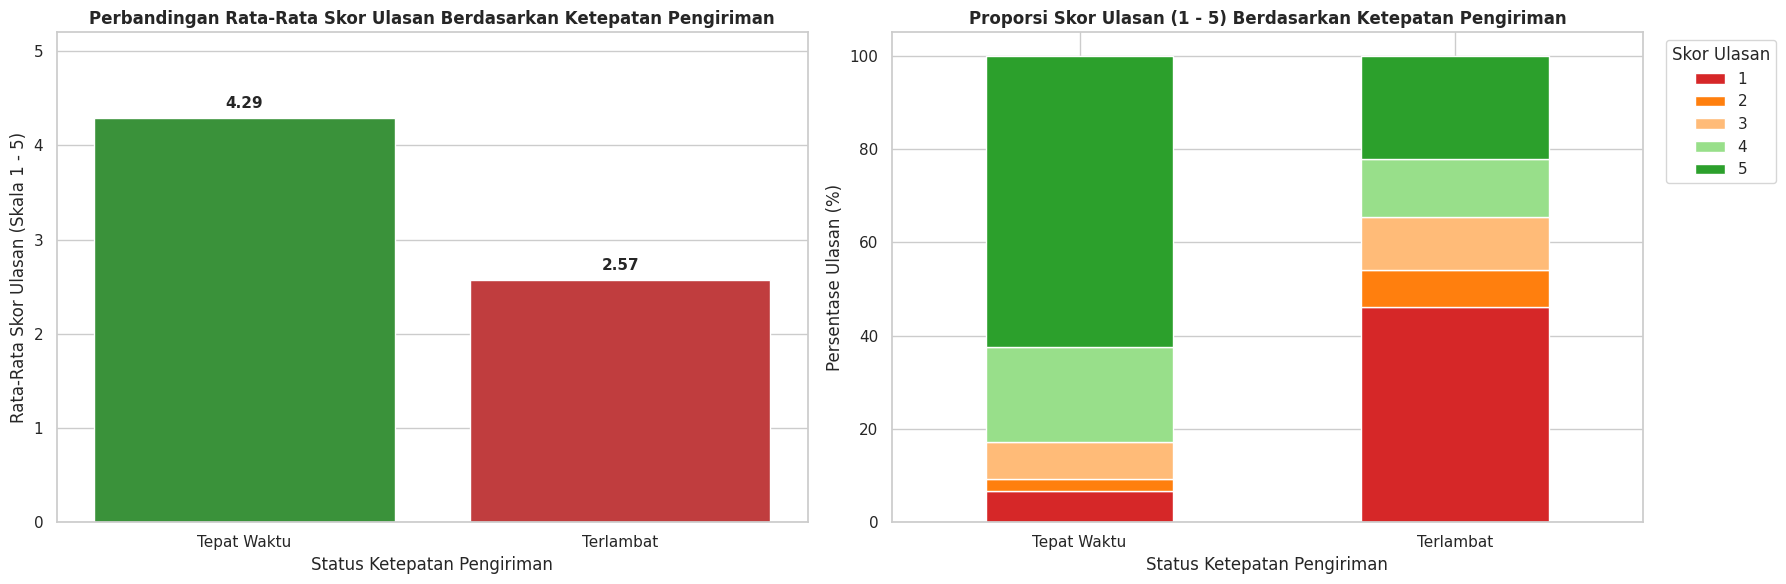

=== RINGKASAN SKOR ULASAN BERDASARKAN KETEPATAN PENGIRIMAN ===
delivery_status  avg_score  total_reviews
    Tepat Waktu   4.293578          88658
      Terlambat   2.566550           7701 

=== PROPORSI SKOR ULASAN (%) ===
review_score         1     2      3      4      5
delivery_status                                  
Tepat Waktu       6.60  2.63   7.99  20.34  62.43
Terlambat        46.15  7.87  11.38  12.39  22.22


In [22]:
# Menggunakan delivery_reviews_df (pesanan yang sudah tiba dan memiliki ulasan)
review_avg_by_status = delivery_reviews_df.groupby("delivery_status", as_index=False).agg(
    avg_score=("review_score", "mean"),
    total_reviews=("review_id", "count")
).sort_values(by="avg_score", ascending=False)

# Menghitung persentase distribusi skor ulasan (1-5) per status pengiriman
score_dist = pd.crosstab(
    delivery_reviews_df["delivery_status"],
    delivery_reviews_df["review_score"],
    normalize="index"
) * 100
score_dist = score_dist.reindex(["Tepat Waktu", "Terlambat"])

# Membuat visualisasi dua panel berdampingan
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(18, 6))

# Panel 1: Perbandingan Rata-Rata Skor Ulasan
sns.barplot(
    data=review_avg_by_status,
    x="delivery_status",
    y="avg_score",
    hue="delivery_status",
    palette={"Tepat Waktu": "#2ca02c", "Terlambat": "#d62728"},
    legend=False,
    ax=ax[0]
)
ax[0].set_title("Perbandingan Rata-Rata Skor Ulasan Berdasarkan Ketepatan Pengiriman", fontsize=12, fontweight="bold")
ax[0].set_xlabel("Status Ketepatan Pengiriman")
ax[0].set_ylabel("Rata-Rata Skor Ulasan (Skala 1 - 5)")
ax[0].set_ylim(0, 5.2)

# Menambahkan anotasi nilai rata-rata di atas setiap batang
for p in ax[0].patches:
    ax[0].annotate(
        f"{p.get_height():.2f}",
        (p.get_x() + p.get_width() / 2., p.get_height()),
        ha="center", va="bottom", fontsize=11, fontweight="bold", xytext=(0, 5), textcoords="offset points"
    )

# Panel 2: Proporsi Skor Ulasan (1 - 5 Bintang) per Status Pengiriman
score_dist.plot(
    kind="bar",
    stacked=True,
    color=["#d62728", "#ff7f0e", "#ffbb78", "#98df8a", "#2ca02c"],
    ax=ax[1],
    rot=0
)
ax[1].set_title("Proporsi Skor Ulasan (1 - 5) Berdasarkan Ketepatan Pengiriman", fontsize=12, fontweight="bold")
ax[1].set_xlabel("Status Ketepatan Pengiriman")
ax[1].set_ylabel("Persentase Ulasan (%)")
ax[1].legend(title="Skor Ulasan", bbox_to_anchor=(1.02, 1), loc="upper left")

plt.tight_layout()
plt.show()

# Menampilkan ringkasan persentase skor bintang 1 dan bintang 5
print("=== RINGKASAN SKOR ULASAN BERDASARKAN KETEPATAN PENGIRIMAN ===")
print(review_avg_by_status.to_string(index=False), "\n")
print("=== PROPORSI SKOR ULASAN (%) ===")
print(score_dist.round(2))

**Insight:**
* **Penurunan Tajam Kepuasan Akibat Keterlambatan:** Ketepatan waktu pengiriman terbukti menjadi faktor krusial yang memengaruhi kepuasan pelanggan. Pesanan yang tiba **tepat waktu** (**88.658 ulasan**) memperoleh rata-rata skor ulasan tinggi sebesar **4,29**, sedangkan pesanan yang mengalami **keterlambatan** (**7.701 ulasan**) mengalami penurunan skor ulasan secara tajam hingga rata-rata **2,57** (selisih penurunan **1,72 poin**).
* **Pergeseran Distribusi Skor Bintang:** Pada pengiriman **tepat waktu**, mayoritas pelanggan memberikan kepuasan maksimal dengan skor **5** (**62,43%**) dan skor **4** (**20,34%**), sementara ulasan terburuk (skor **1**) hanya sebesar **6,60%**. Sebaliknya, pada pengiriman **terlambat**, proporsi ulasan skor **1** melonjak drastis menjadi **46,15%**, sedangkan skor **5** menyusut menjadi **22,22%**.
* **Rekomendasi Operasional:** Perusahaan perlu mengimplementasikan sistem peringatan dini (*early warning system*) pada alur pemantauan logistik untuk mendeteksi potensi keterlambatan pengiriman sebelum melewati batas estimasi, disertai kompensasi proaktif (seperti voucher potongan belanja) bagi pelanggan yang terdampak keterlambatan guna menjaga tingkat kepuasan dan retensi.

## **Analisis Lanjutan: RFM Analysis**

Analisis lanjutan ini dilakukan untuk mengelompokkan pelanggan berdasarkan 3 parameter utama:
1. **Recency:** Jumlah hari sejak transaksi terakhir pelanggan.
2. **Frequency:** Jumlah total transaksi yang dilakukan oleh pelanggan.
3. **Monetary:** Total nilai pengeluaran (uang) yang dihabiskan oleh pelanggan.

In [23]:
# Membuat skor kuartil (1-4) untuk Recency dan Monetary dari rfm_df
rfm_segment_df = rfm_df.copy()

# Skor Recency: semakin kecil jumlah hari (semakin baru belanja), semakin tinggi skornya (4)
rfm_segment_df["r_score"] = pd.qcut(rfm_segment_df["recency"], q=4, labels=[4, 3, 2, 1]).astype(int)

# Skor Frequency berbasis aturan bisnis aktual (karena 96,88% pelanggan hanya bertransaksi 1 kali)
def score_frequency(freq):
    if freq == 1:
        return 1
    elif freq == 2:
        return 2
    elif freq == 3:
        return 3
    else:
        return 4

rfm_segment_df["f_score"] = rfm_segment_df["frequency"].apply(score_frequency)

# Skor Monetary berbasis kuartil pengeluaran
rfm_segment_df["m_score"] = pd.qcut(rfm_segment_df["monetary"], q=4, labels=[1, 2, 3, 4]).astype(int)

# Menggabungkan skor RFM dan mengelompokkan segmen pelanggan
rfm_segment_df["rfm_score"] = rfm_segment_df["r_score"] + rfm_segment_df["f_score"] + rfm_segment_df["m_score"]

def segment_customer(row):
    if row["rfm_score"] >= 9 and row["frequency"] >= 2:
        return "Champions"
    elif row["rfm_score"] >= 8:
        return "Loyal Customers"
    elif row["rfm_score"] >= 6:
        return "Potential Loyalist"
    else:
        return "At Risk / Hibernating"

rfm_segment_df["customer_segment"] = rfm_segment_df.apply(segment_customer, axis=1)

print("=== DISTRIBUSI SEGMEN PELANGGAN (RFM SEGMENTATION) ===")
print(rfm_segment_df["customer_segment"].value_counts())
print("\n=== 5 DATA TERATAS HASIL SEGMENTASI RFM ===")
print(rfm_segment_df[["customer_unique_id", "recency", "frequency", "monetary", "rfm_score", "customer_segment"]].head())

=== DISTRIBUSI SEGMEN PELANGGAN (RFM SEGMENTATION) ===
customer_segment
Potential Loyalist       40978
At Risk / Hibernating    35961
Loyal Customers          17823
Champions                 1333
Name: count, dtype: int64

=== 5 DATA TERATAS HASIL SEGMENTASI RFM ===
                 customer_unique_id  recency  frequency  monetary  rfm_score  \
0  0000366f3b9a7992bf8c76cfdf3221e2      161          1    141.90          8   
1  0000b849f77a49e4a4ce2b2a4ca5be3f      164          1     27.19          6   
2  0000f46a3911fa3c0805444483337064      586          1     86.22          4   
3  0000f6ccb0745a6a4b88665a16c9f078      370          1     43.62          4   
4  0004aac84e0df4da2b147fca70cf8255      337          1    196.89          7   

        customer_segment  
0        Loyal Customers  
1     Potential Loyalist  
2  At Risk / Hibernating  
3  At Risk / Hibernating  
4     Potential Loyalist  


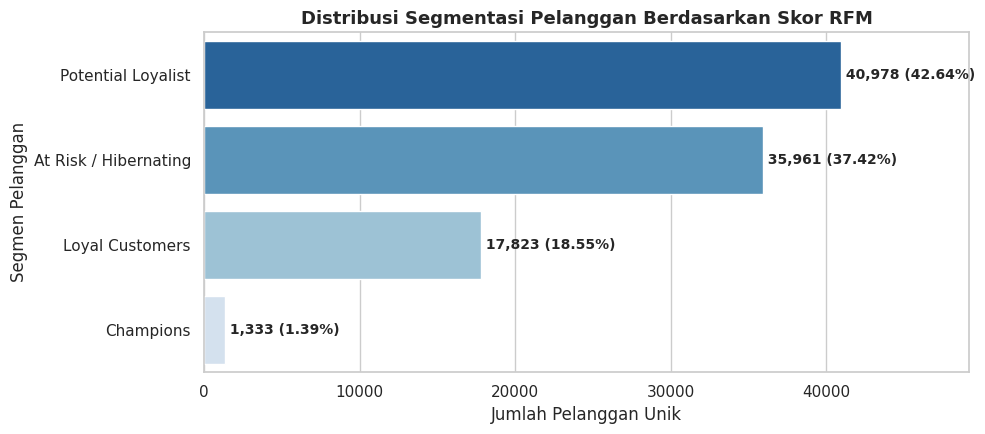

In [25]:
segment_counts = rfm_segment_df["customer_segment"].value_counts().reset_index()
segment_counts.columns = ["customer_segment", "total_customers"]
segment_counts["percentage"] = (segment_counts["total_customers"] / len(rfm_segment_df)) * 100

plt.figure(figsize=(10, 4.5))
ax = sns.barplot(
    x="total_customers",
    y="customer_segment",
    data=segment_counts,
    hue="customer_segment",
    palette="Blues_r",
    legend=False
)

# Menambahkan anotasi jumlah dan persentase di ujung batang
for p, pct in zip(ax.patches, segment_counts["percentage"]):
    ax.annotate(
        f" {int(p.get_width()):,} ({pct:.2f}%)",
        (p.get_width(), p.get_y() + p.get_height() / 2.),
        ha="left", va="center", fontsize=10, fontweight="bold"
    )

plt.title("Distribusi Segmentasi Pelanggan Berdasarkan Skor RFM", fontsize=13, fontweight="bold")
plt.xlabel("Jumlah Pelanggan Unik")
plt.ylabel("Segmen Pelanggan")
plt.xlim(0, segment_counts["total_customers"].max() * 1.2)
plt.tight_layout()
plt.show()

**Insight:**
* **Dominasi Segmen *Potential Loyalist* dan *At Risk / Hibernating*:** Mayoritas basis pelanggan berada pada segmen **Potential Loyalist** sebanyak **40.978 pelanggan (42,64%)** dan **At Risk / Hibernating** sebanyak **35.961 pelanggan (37,42%)**. Tingginya porsi pada kedua segmen ini mencerminkan karakteristik perilaku belanja pelanggan yang umumnya hanya bertransaksi satu kali (*single order*) dan mulai lama tidak kembali bertransaksi.
* **Kelompok Pelanggan Bernilai Tinggi (*Loyal Customers* dan *Champions*):** Segmen **Loyal Customers** mencakup **17.823 pelanggan (18,55%)** yang memiliki kebaruan transaksi (*recency*) dan nilai belanja (*monetary*) di atas rata-rata. Sementara itu, segmen paling bernilai yaitu **Champions** berjumlah **1.333 pelanggan (1,39%)** yang secara konsisten melakukan pembelian berulang (*repeat order*) dengan kontribusi belanja tinggi.
* **Strategi Pemasaran Terarah:** Perusahaan dapat memfokuskan kampanye pengaktifan kembali (*re-engagement* melalui promo personalisasi) bagi **35.961 pelanggan** di segmen *At Risk / Hibernating*, mendorong transaksi kedua pada segmen *Potential Loyalist*, serta memberikan program loyalitas eksklusif (seperti akses promo lebih awal atau bebas ongkos kirim prioritas) bagi **1.333 pelanggan** pada segmen *Champions*.

## Conclusion & Recommendation

### Conclusion

Berdasarkan rangkaian proses analisis data transaksi E-Commerce Olist pada periode September 2016 hingga Oktober 2018, diperoleh lima kesimpulan utama yang menjawab seluruh pertanyaan bisnis:

1. **Perilaku Pelanggan Berdasarkan Analisis RFM & Segmentasi (Pertanyaan 1 & Analisis Lanjutan):**
   Dari total **96.095 pelanggan unik**, tingkat retensi tergolong sangat rendah karena **93.098 pelanggan (96,88%)** hanya melakukan satu kali transaksi (*Single Order*), sedangkan pelanggan dengan pembelian berulang (*Repeat Order*) hanya berjumlah **2.997 pelanggan (3,12%)**. Mayoritas pelanggan memiliki rentang transaksi terakhir (*recency*) antara **100 hingga 400 hari** dengan median **269 hari** (rata-rata **288,73 hari**), serta median total belanja (*monetary*) sebesar **108,00 BRL** (rata-rata **166,59 BRL**). Melalui pemetaan skor RFM, basis pelanggan terbagi ke dalam segmen **Potential Loyalist** (**40.978 pelanggan** atau **42,64%**), **At Risk / Hibernating** (**35.961 pelanggan** atau **37,42%**), **Loyal Customers** (**17.823 pelanggan** atau **18,55%**), dan **Champions** (**1.333 pelanggan** atau **1,39%**).

2. **Kinerja Kategori Produk Berdasarkan Volume dan Pendapatan (Pertanyaan 2):**
   Kategori dengan volume penjualan tertinggi berbeda dengan kategori penyumbang pendapatan terbesar. Dari sisi kuantitas, `cama_mesa_banho` (perlengkapan rumah tangga) menempati urutan pertama dengan **11.115 item terjual** (pendapatan **1.036.988,68 BRL**), diikuti oleh `beleza_saude` (**9.670 item**) dan `esporte_lazer` (**8.641 item**). Namun, dari sisi total pendapatan, `beleza_saude` (kecantikan dan kesehatan) menjadi kontributor terbesar senilai **1.258.681,34 BRL**, disusul oleh `relogios_presentes` (jam tangan dan hadiah) sebesar **1.205.005,68 BRL** dengan harga rata-rata per unit yang lebih tinggi (**5.991 item terjual**).

3. **Dominasi Metode Pembayaran dan Pola Cicilan (Pertanyaan 3):**
   Metode pembayaran kartu kredit (`credit_card`) mendominasi transaksi secara signifikan dengan **76.505 pesanan unik**, jauh melampaui `boleto` (**19.784 pesanan**), `voucher` (**3.866 pesanan**), dan `debit_card` (**1.528 pesanan**). Dari **76.793 transaksi** kartu kredit yang valid, sebanyak **66,85%** (**51.338 transaksi**) memanfaatkan fasilitas cicilan lebih dari 1 kali dengan rata-rata **3,51 kali** cicilan (nilai tengah **3 kali**), terutama pada tenor **2x, 3x, hingga 10x ke atas**.

4. **Persebaran Geografis Pelanggan dan Pendapatan (Pertanyaan 4):**
   Aktivitas transaksi terkonsentrasi sangat kuat di wilayah tenggara Brasil. Negara bagian **São Paulo (`SP`)** menduduki peringkat pertama dengan **40.301 pelanggan unik** dan pendapatan sebesar **5.998.226,96 BRL**, diikuti oleh **Rio de Janeiro (`RJ`)** (**12.384 pelanggan unik**; **2.144.379,69 BRL**) dan **Minas Gerais (`MG`)** (**11.259 pelanggan unik**; **1.872.257,26 BRL**). Secara gabungan, ketiga negara bagian ini menyumbang **66,51%** dari seluruh pelanggan unik dan **62,56%** dari total pendapatan platform.

5. **Dampak Ketepatan Waktu Pengiriman terhadap Kepuasan Pelanggan (Pertanyaan 5):**
   Ketepatan pengiriman berpengaruh sangat besar terhadap penilaian pelanggan. Pesanan yang tiba **tepat waktu** (**88.658 ulasan**) memperoleh rata-rata skor ulasan tinggi sebesar **4,29**, dengan **62,43%** di antaranya meraih skor bintang **5** dan hanya **6,60%** yang mendapat skor bintang **1**. Sebaliknya, pada pesanan yang mengalami **keterlambatan** (**7.701 ulasan**), rata-rata skor ulasan menurun tajam menjadi **2,57** (selisih **1,72 poin**), di mana proporsi ulasan bintang **1** melonjak hingga **46,15%**.

### Rekomendasi Action Item

* **Program Retensi dan Reaktivasi Berbasis Segmen RFM:** Meluncurkan kampanye pengaktifan kembali (*re-engagement*) melalui kupon potongan harga terpersonalisasi bagi **35.961 pelanggan** di segmen *At Risk / Hibernating*, mendorong transaksi kedua pada segmen *Potential Loyalist* (**40.978 pelanggan**), serta memberikan hak istimewa (seperti bebas ongkos kirim prioritas dan akses promo lebih awal) untuk mempertahankan **1.333 pelanggan** pada segmen *Champions*.
* **Optimalisasi Stok dan Strategi *Bundling* Kategori Unggulan:** Memprioritaskan ketersediaan stok pengaman (*safety stock*) pada kategori bervolume tinggi seperti `cama_mesa_banho` serta merancang paket *bundling* lintas kategori bersama kategori bernilai jual tinggi seperti `beleza_saude` dan `relogios_presentes` untuk meningkatkan nilai keranjang belanja rata-rata (*average order value*).
* **Kemitraan Promo Cicilan Kartu Kredit:** Bekerja sama dengan mitra perbankan penerbit kartu kredit untuk menghadirkan program **cicilan 0%** pada tenor populer (**3x hingga 10x**) guna memaksimalkan konversi pembelian pada produk berharga menengah hingga tinggi.
* **Penguatan Kapasitas Logistik Wilayah Tenggara dan Sistem Peringatan Dini:** Memfokuskan ekspansi kapasitas pusat pemenuhan pesanan (*fulfillment center*) di koridor **São Paulo (`SP`), Rio de Janeiro (`RJ`), dan Minas Gerais (`MG`)** yang mencakup lebih dari **62%** pendapatan, sekaligus menerapkan sistem peringatan dini (*early warning system*) pemantauan pengiriman dan kompensasi voucher otomatis apabila pesanan berpotensi melewati batas estimasi waktu tiba.